# Assignment 6 — K-Means Clustering

**Name: Parth Isekar | Roll no : 327** 

**AI-ML Lab | Practical Assignment 6**

**Aim:** Implement K-means manually for seven customers, apply scikit-learn KMeans and the elbow method to 60 students, and interpret the resulting groups.


**K-means:** Assign each point to its nearest centroid, then update each centroid using the mean of its assigned points. Repeat until the centroids no longer move.

## Part A — K-means from scratch (K = 2)

### A1. Load and check `customers_7.csv`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

customers = pd.read_csv("customers_7.csv")
print("Dataset shape:", customers.shape)
print(customers.to_string(index=False))
print("\nMissing values:", customers.isna().sum().to_dict())
print("Duplicate customer IDs:", customers["customer"].duplicated().sum())

assert customers.shape == (7, 3)
assert not customers.isna().any().any()
assert customers["customer"].is_unique

# 'customer' is an identifier, not a numeric clustering feature.
X_customers = customers[["visits_per_month", "spend_rs_1000"]].to_numpy(dtype=float)

Dataset shape: (7, 3)
customer  visits_per_month  spend_rs_1000
      P1               1.0            1.0
      P2               1.5            2.0
      P3               3.0            4.0
      P4               5.0            7.0
      P5               3.5            5.0
      P6               4.5            5.0
      P7               3.5            4.5

Missing values: {'customer': 0, 'visits_per_month': 0, 'spend_rs_1000': 0}
Duplicate customer IDs: 0


### A2. Euclidean distance and manual K-means

Distance between points \(p\) and \(q\):

\[d(p,q)=\sqrt{(p_1-q_1)^2+(p_2-q_2)^2}\]

Use **P1 and P4** as the initial centroids. If distances tie, `argmin()` chooses the first centroid (C1), matching the supplied hand calculation. The following function uses **no scikit-learn**.

In [2]:
def euclidean(p, q):
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    return float(np.sqrt(np.sum((p - q) ** 2)))


def kmeans_scratch(X, initial_centroids):
    centroids = np.array(initial_centroids, dtype=float, copy=True)
    iteration = 0

    while True:
        iteration += 1
        distances = np.array([
            [euclidean(point, center) for center in centroids]
            for point in X
        ])
        labels = np.argmin(distances, axis=1)  # A tie goes to C1.

        print(f"\nIteration {iteration}")
        print(f"Starting centroids: C1 = {centroids[0]}, C2 = {centroids[1]}")
        iteration_table = pd.DataFrame({
            "Customer": customers["customer"],
            "Distance to C1": np.round(distances[:, 0], 2),
            "Distance to C2": np.round(distances[:, 1], 2),
            "Assigned cluster": [f"C{value + 1}" for value in labels]
        })
        print(iteration_table.to_string(index=False))

        new_centroids = []
        for cluster_index in range(len(centroids)):
            points = X[labels == cluster_index]
            if len(points) == 0:
                raise ValueError("A cluster became empty; its mean cannot be calculated.")
            new_centroids.append(points.mean(axis=0))
        new_centroids = np.array(new_centroids)

        print("Updated centroids:",
              f"C1 = {np.round(new_centroids[0], 4)},",
              f"C2 = {np.round(new_centroids[1], 4)}")
        if np.allclose(new_centroids, centroids):
            print("Centroids unchanged: algorithm converged.")
            return labels, new_centroids, iteration
        centroids = new_centroids


initial_centroids = customers.set_index("customer").loc[
    ["P1", "P4"], ["visits_per_month", "spend_rs_1000"]
].to_numpy(dtype=float)

customer_labels, customer_centroids, customer_iterations = kmeans_scratch(
    X_customers, initial_centroids
)


Iteration 1
Starting centroids: C1 = [1. 1.], C2 = [5. 7.]
Customer  Distance to C1  Distance to C2 Assigned cluster
      P1            0.00            7.21               C1
      P2            1.12            6.10               C1
      P3            3.61            3.61               C1
      P4            7.21            0.00               C2
      P5            4.72            2.50               C2
      P6            5.32            2.06               C2
      P7            4.30            2.92               C2
Updated centroids: C1 = [1.8333 2.3333], C2 = [4.125 5.375]

Iteration 2
Starting centroids: C1 = [1.83333333 2.33333333], C2 = [4.125 5.375]
Customer  Distance to C1  Distance to C2 Assigned cluster
      P1            1.57            5.38               C1
      P2            0.47            4.28               C1
      P3            2.03            1.78               C2
      P4            5.64            1.85               C2
      P5            3.14            0.73    

### A3. Check against Section 3 of the supplied K-means handout

In [3]:
expected_labels = np.array([0, 0, 1, 1, 1, 1, 1])
expected_centroids = np.array([[1.25, 1.50], [3.90, 5.10]])

checks = {
    "3 iterations": customer_iterations == 3,
    "P1 and P2 in C1; P3-P7 in C2": np.array_equal(customer_labels, expected_labels),
    "Final centroids match hand calculation": np.allclose(customer_centroids, expected_centroids)
}
for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")
assert all(checks.values())

customer_results = customers.copy()
customer_results["Cluster"] = [f"C{i + 1}" for i in customer_labels]
print("\nFinal customer groups:")
print(customer_results.to_string(index=False))

customer_wcss = sum(
    euclidean(point, customer_centroids[label]) ** 2
    for point, label in zip(X_customers, customer_labels)
)
print(f"Final WCSS: {customer_wcss:.3f}")

3 iterations: PASS
P1 and P2 in C1; P3-P7 in C2: PASS
Final centroids match hand calculation: PASS

Final customer groups:
customer  visits_per_month  spend_rs_1000 Cluster
      P1               1.0            1.0      C1
      P2               1.5            2.0      C1
      P3               3.0            4.0      C2
      P4               5.0            7.0      C2
      P5               3.5            5.0      C2
      P6               4.5            5.0      C2
      P7               3.5            4.5      C2
Final WCSS: 8.525


### A4. Plot customer clusters and final centroids

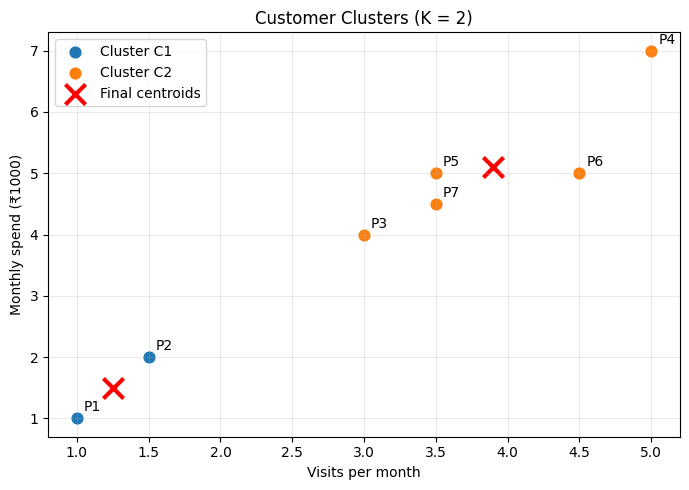

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
for label in [0, 1]:
    points = X_customers[customer_labels == label]
    ax.scatter(points[:, 0], points[:, 1], label=f"Cluster C{label + 1}", s=60)

for customer_id, point in zip(customers["customer"], X_customers):
    ax.annotate(customer_id, (point[0], point[1]), xytext=(5, 5), textcoords="offset points")

ax.scatter(customer_centroids[:, 0], customer_centroids[:, 1],
           marker="x", s=210, color="red", linewidths=3, label="Final centroids")
ax.set(title="Customer Clusters (K = 2)", xlabel="Visits per month",
       ylabel="Monthly spend (₹1000)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("customer_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## Part B — scikit-learn KMeans and elbow method

### B1. Load `student_marks_60.csv`

Both clustering features are marks out of 100; they have the same units and range, so scaling is not required here. `roll_no` is an identifier and is excluded. Missing values are checked before fitting.

In [5]:
students = pd.read_csv("student_marks_60.csv")
print("Dataset shape:", students.shape)
print("First five rows:")
print(students.head().to_string(index=False))
print("\nMissing values:", students.isna().sum().to_dict())
print("Duplicate roll numbers:", students["roll_no"].duplicated().sum())

assert students.shape == (60, 3)
assert not students.isna().any().any()
assert students["roll_no"].is_unique
assert students[["theory_marks", "practical_marks"]].apply(lambda col: col.between(0, 100).all()).all()

X_students = students[["theory_marks", "practical_marks"]].to_numpy(dtype=float)

Dataset shape: (60, 3)
First five rows:
roll_no  theory_marks  practical_marks
    S01          36.9             40.1
    S02          35.1             48.9
    S03          80.2             86.3
    S04          41.8             38.8
    S05          89.2             79.4

Missing values: {'roll_no': 0, 'theory_marks': 0, 'practical_marks': 0}
Duplicate roll numbers: 0


### B2. Elbow method for K = 1 to 8

The elbow method compares **WCSS** (*within-cluster sum of squares*), recorded as `inertia_` in scikit-learn. We select the bend where increasing K gives substantially smaller reductions in WCSS.

 K WCSS (inertia)
 1       38751.65
 2       10212.08
 3        2204.73
 4        1765.65
 5        1387.83
 6        1153.07
 7        1003.61
 8         865.77


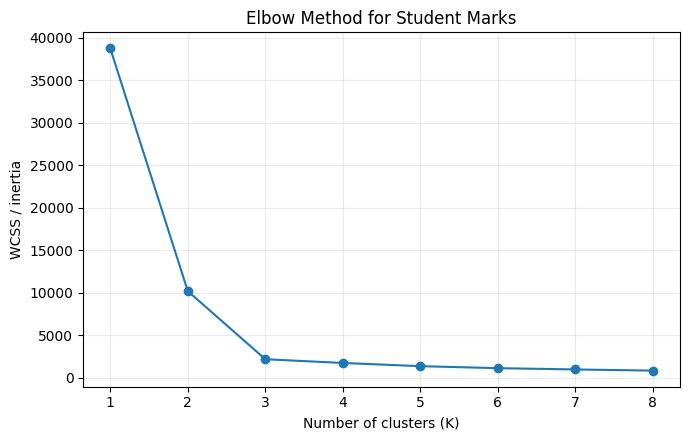

Selected K = 3: WCSS drops sharply from K=1 to K=3, then improvements become smaller.


In [6]:
wcss_values = []
for k in range(1, 9):
    model_k = KMeans(n_clusters=k, random_state=42, n_init=20)
    model_k.fit(X_students)
    wcss_values.append(model_k.inertia_)

elbow_table = pd.DataFrame({"K": range(1, 9), "WCSS (inertia)": wcss_values})
print(elbow_table.to_string(index=False, formatters={"WCSS (inertia)": "{:.2f}".format}))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, 9), wcss_values, marker="o")
ax.set_xticks(range(1, 9))
ax.set(title="Elbow Method for Student Marks", xlabel="Number of clusters (K)",
       ylabel="WCSS / inertia")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("student_elbow.png", dpi=150, bbox_inches="tight")
plt.show()

best_k = 3
print(f"Selected K = {best_k}: WCSS drops sharply from K=1 to K=3, then improvements become smaller.")

### B3. Fit the final model (K = 3) and plot clusters and centroids

Final WCSS: 2204.73
Final centroids (theory, practical):
Cluster 0: (84.13, 86.56)
Cluster 1: (41.42, 44.05)
Cluster 2: (61.05, 69.12)


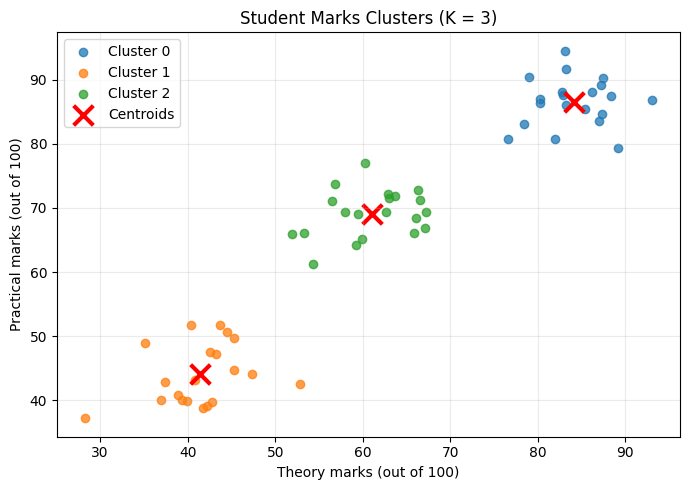

In [7]:
student_model = KMeans(n_clusters=best_k, random_state=42, n_init=20)
student_clusters = student_model.fit_predict(X_students)
student_centroids = student_model.cluster_centers_

print("Final WCSS:", round(student_model.inertia_, 2))
print("Final centroids (theory, practical):")
for cluster_id, center in enumerate(student_centroids):
    print(f"Cluster {cluster_id}: ({center[0]:.2f}, {center[1]:.2f})")

fig, ax = plt.subplots(figsize=(7, 5))
for cluster_id in range(best_k):
    points = X_students[student_clusters == cluster_id]
    ax.scatter(points[:, 0], points[:, 1], label=f"Cluster {cluster_id}", alpha=0.75)

ax.scatter(student_centroids[:, 0], student_centroids[:, 1],
           marker="x", s=200, color="red", linewidths=3, label="Centroids")
ax.set(title="Student Marks Clusters (K = 3)",
       xlabel="Theory marks (out of 100)", ylabel="Practical marks (out of 100)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("student_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## Part C — Interpretation and prediction

### C1–C2. Cluster sizes, mean marks and meaningful names

In [8]:
students_result = students.copy()
students_result["Cluster"] = student_clusters

summary = students_result.groupby("Cluster").agg(
    Students=("roll_no", "count"),
    Avg_Theory=("theory_marks", "mean"),
    Avg_Practical=("practical_marks", "mean")
)

# Give names according to the mean marks, rather than relying on arbitrary cluster IDs.
order = summary[["Avg_Theory", "Avg_Practical"]].mean(axis=1).sort_values().index
cluster_names = dict(zip(order, ["Remedial batch", "Regular batch", "Advanced batch"]))
summary["Group name"] = summary.index.map(cluster_names)

print("Cluster summary:")
print(summary[["Group name", "Students", "Avg_Theory", "Avg_Practical"]].round(2).to_string())
print("Total students:", int(summary["Students"].sum()))

Cluster summary:
             Group name  Students  Avg_Theory  Avg_Practical
Cluster                                                     
0        Advanced batch        20       84.13          86.56
1        Remedial batch        20       41.42          44.04
2         Regular batch        20       61.04          69.12
Total students: 60


### C3. Predict group for a new student with marks (70, 72)

In [9]:
new_student = np.array([[70.0, 72.0]])
new_cluster = int(student_model.predict(new_student)[0])
print("New student marks: Theory = 70, Practical = 72")
print("Predicted cluster:", new_cluster)
print("Predicted group:", cluster_names[new_cluster])

New student marks: Theory = 70, Practical = 72
Predicted cluster: 2
Predicted group: Regular batch


## Conclusion

**Part A:** Manual K-means converged in 3 iterations. C1 contains P1 and P2 with centroid (1.25, 1.50); C2 contains P3–P7 with centroid (3.90, 5.10). These match the worked example.

**Part B:** The elbow curve supports K = 3 for student marks. WCSS measures how close students are to their cluster centroids; lower WCSS is better for a fixed K, but K should not be increased without considering the elbow.

**Part C:** Clusters can be interpreted as remedial, regular and advanced batches using their average theory and practical marks. The predicted group for a student scoring (70, 72) is shown above.